In [1]:
import pandas as pd

df = pd.read_csv("StudentPerformanceFactors.csv")

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
print("Number of rows and columns:", df.shape)

df[["Hours_Studied", "Attendance", "Previous_Scores", "Exam_Score"]].head() 

Number of rows and columns: (6607, 20)


,Hours_Studied,Attendance,Previous_Scores,Exam_Score
0,23,84,73,67
1,19,64,59,61
2,24,98,91,74
3,29,89,98,71
4,19,92,65,70


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [4]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [6]:
df_clean = df.copy()

df_clean["Teacher_Quality"].fillna(
    df_clean["Teacher_Quality"].mode()[0], inplace=True
)

df_clean["Parental_Education_Level"].fillna(
    df_clean["Parental_Education_Level"].mode()[0], inplace=True
)

df_clean["Distance_from_Home"].fillna(
    df_clean["Distance_from_Home"].mode()[0], inplace=True
)

df_clean.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

In [7]:
def descriptive_analysis(data, column):
    results = {
        "Mean": data[column].mean(),
        "Median": data[column].median(),
        "Mode": data[column].mode()[0],
        "Minimum": data[column].min(),
        "Maximum": data[column].max(),
        "Range": data[column].max() - data[column].min(),
        "Standard Deviation": data[column].std(),
        "Variance": data[column].var()
    }
    
    return results

In [8]:
descriptive_analysis(df_clean, "Exam_Score")

{'Mean': 67.23565914938702,
 'Median': 67.0,
 'Mode': 68,
 'Minimum': 55,
 'Maximum': 101,
 'Range': 46,
 'Standard Deviation': 3.890455781261724,
 'Variance': 15.135646185952773}

In [9]:
sample_size = 150

random_sample = df_clean.sample(
    n=sample_size,
    replace=False,
    random_state=42
)

descriptive_analysis(random_sample, "Exam_Score")

{'Mean': 67.40666666666667,
 'Median': 67.0,
 'Mode': 67,
 'Minimum': 55,
 'Maximum': 89,
 'Range': 34,
 'Standard Deviation': 4.122449045137356,
 'Variance': 16.9945861297539}

In [10]:
sample_size = 150
interval = len(df_clean) // sample_size

systematic_sample = df_clean.iloc[::interval].head(sample_size)

descriptive_analysis(systematic_sample, "Exam_Score")

{'Mean': 67.98666666666666,
 'Median': 67.0,
 'Mode': 66,
 'Minimum': 61,
 'Maximum': 94,
 'Range': 33,
 'Standard Deviation': 4.714658942972002,
 'Variance': 22.228008948545877}

In [11]:
def descriptive_analysis(data, column):
    results = {
        "Count": data[column].count(),
        "Mean": data[column].mean(),
        "Median": data[column].median(),
        "Mode": data[column].mode()[0],
        "Minimum": data[column].min(),
        "Q1": data[column].quantile(0.25),
        "Q2": data[column].quantile(0.50),
        "Q3": data[column].quantile(0.75),
        "Maximum": data[column].max(),
        "Range": data[column].max() - data[column].min(),
        "IQR": data[column].quantile(0.75) - data[column].quantile(0.25),
        "Standard Deviation": data[column].std(),
        "Variance": data[column].var(),
        "Skewness": data[column].skew(),
        "Kurtosis": data[column].kurt()
    }

    return results

In [12]:
descriptive_analysis(df_clean, "Exam_Score")

{'Count': 6607,
 'Mean': 67.23565914938702,
 'Median': 67.0,
 'Mode': 68,
 'Minimum': 55,
 'Q1': 65.0,
 'Q2': 67.0,
 'Q3': 69.0,
 'Maximum': 101,
 'Range': 46,
 'IQR': 4.0,
 'Standard Deviation': 3.890455781261724,
 'Variance': 15.135646185952773,
 'Skewness': 1.6448082853982677,
 'Kurtosis': 10.575422734795485}

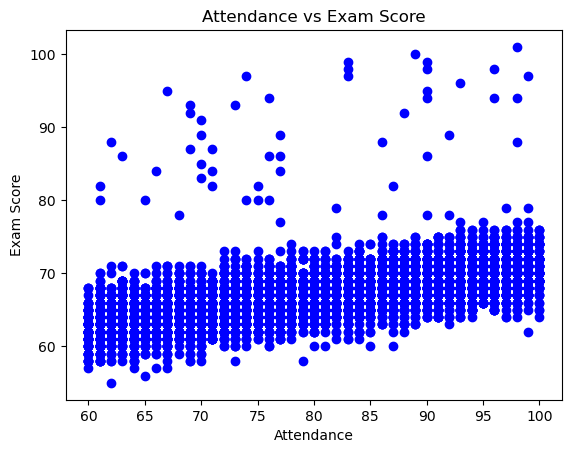

In [13]:
import matplotlib.pyplot as plt

plt.scatter(
    df_clean["Attendance"],
    df_clean["Exam_Score"],
    color="blue"
)

plt.xlabel("Attendance")
plt.ylabel("Exam Score")
plt.title("Attendance vs Exam Score")
plt.show()

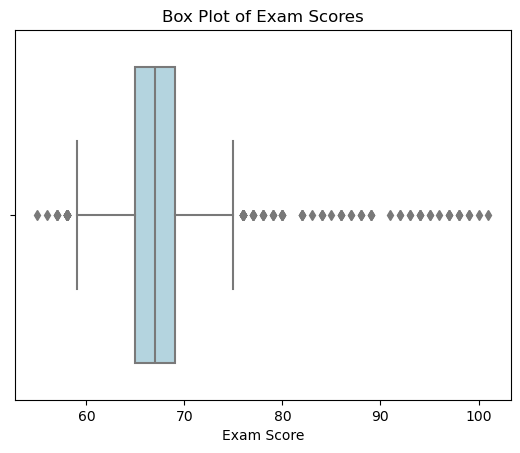

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df_clean["Exam_Score"], color="lightblue")

plt.xlabel("Exam Score")
plt.title("Box Plot of Exam Scores")
plt.show()

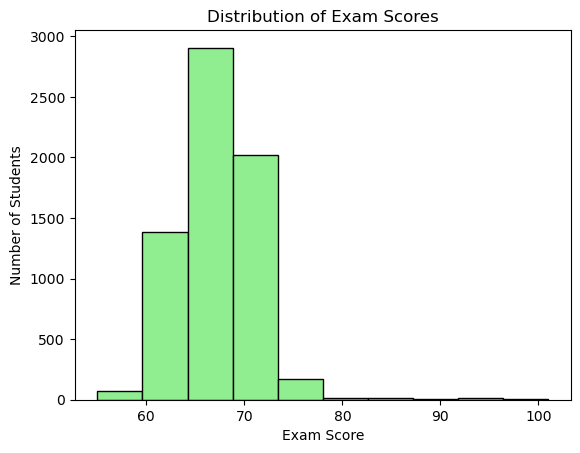

In [15]:
import matplotlib.pyplot as plt

plt.hist(
    df_clean["Exam_Score"],
    bins=10,
    color="lightgreen",
    edgecolor="black"
)

plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.title("Distribution of Exam Scores")
plt.show()

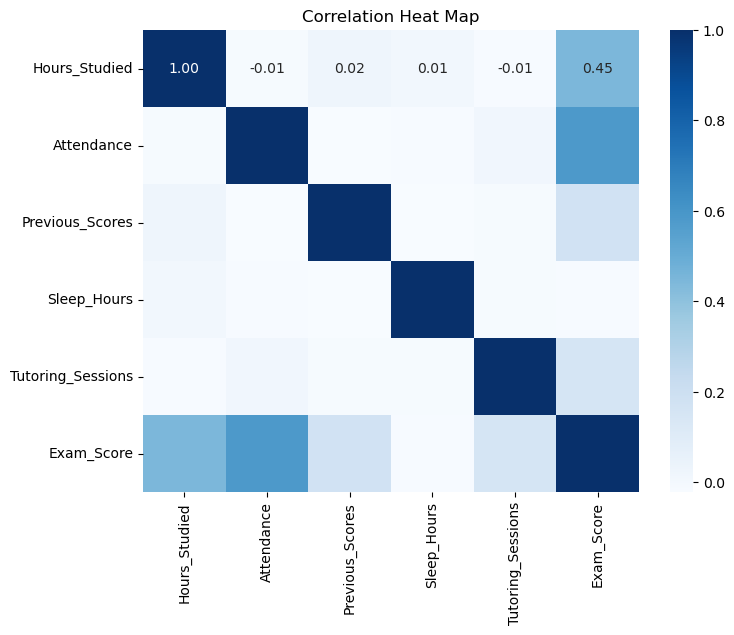

In [16]:
columns = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
    "Exam_Score"
]

correlation = df_clean[columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Heat Map")
plt.show()

In [17]:
from scipy.stats import pearsonr

pearson_result, pearson_pvalue = pearsonr(
    df_clean["Attendance"],
    df_clean["Exam_Score"]
)

print("Pearson correlation:", pearson_result)
print("P-value:", pearson_pvalue)

Pearson correlation: 0.5810718633120641
P-value: 0.0


In [18]:
from scipy.stats import spearmanr

spearman_result, spearman_pvalue = spearmanr(
    df_clean["Attendance"],
    df_clean["Exam_Score"]
)

print("Spearman correlation:", spearman_result)
print("P-value:", spearman_pvalue)

Spearman correlation: 0.6723661464413685
P-value: 0.0


In [19]:
from scipy.stats import chi2_contingency

df_clean["Score_Category"] = pd.cut(
    df_clean["Exam_Score"],
    bins=[0, 64, 69, float("inf")],
    labels=["Low", "Average", "High"]
)

table = pd.crosstab(
    df_clean["Parental_Involvement"],
    df_clean["Score_Category"]
)

chi2, chi_pvalue, dof, expected = chi2_contingency(table)

print(table)
print("Chi-square value:", chi2)
print("P-value:", chi_pvalue)

Score_Category        Low  Average  High
Parental_Involvement                    
High                  283     1016   609
Low                   408      700   229
Medium                761     1814   787
Chi-square value: 163.65379482738916
P-value: 2.4054779238093558e-34


In [20]:
from scipy.stats import ttest_1samp

population_mean = df_clean["Exam_Score"].mean()

t_value, t_pvalue = ttest_1samp(
    random_sample["Exam_Score"],
    popmean=population_mean
)

print("Population mean:", population_mean)
print("Sample mean:", random_sample["Exam_Score"].mean())
print("T-value:", t_value)
print("P-value:", t_pvalue)

Population mean: 67.23565914938702
Sample mean: 67.40666666666667
T-value: 0.5080489230175042
P-value: 0.6121703345045606
